# Fraud Prevention Case – Transaction Classification

**Problem:** the analysis of suspicious transactions is mostly manual and does not scale, creating two risks: frauds not detected in time (financial loss) and legitimate customers being blocked (bad experience).

**Goal:** build a Machine Learning model that classifies transactions as fraudulent or not fraudulent.

**Deliverables:** this notebook, the January/2026 dataset classified and a presentation.

*Note: the original column names of the datasets (in Portuguese) were kept as provided. Amounts are assumed to be in Brazilian reais (R$), since all cities and postal codes are Brazilian; the dataset does not state the currency.*

## 0. Setup
Importing the libraries and loading the datasets (done only once here; the other sections reuse data2025 and data2026).

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Some charts use the seaborn library.
import seaborn as sns

# Simple settings to improve how tables are displayed.
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

# General settings to improve how charts look
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 5)
plt.rcParams["font.size"] = 12

In [51]:
from google.colab import drive
drive.mount('/content/drive/')

folder = '/content/drive/MyDrive/testes/ATF-Data_Science/'

# 2025 history (with the flag_fraude label) -> used to train and test the model
data2025 = pd.read_csv(folder + 'transacoes_historico_2025.csv')

# January/2026 (no label) -> dataset the model will classify (scoring)
data2026 = pd.read_csv(folder + 'transacoes_jan2026.csv')

print("2025 history: ", data2025.shape)
print("January 2026: ", data2026.shape)

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).
2025 history:  (523525, 15)
January 2026:  (44451, 14)


## 1. Understanding the problem

Based on the context, this is a supervised binary classification problem: using the 2025 history, where each transaction is already marked as fraud or not (flag_fraude), the model learns patterns to classify new transactions.

The model can make two types of error:
- False negative: letting a fraud go through → financial loss.
- False positive: blocking a legitimate customer → bad experience and customer service cost.

Since frauds are rare, accuracy is not a good metric, so the model will be evaluated by precision (of the alerts, how many are fraud) and recall (of the frauds, how many were detected).

## 2. Data quality
Goal: make sure the datasets are complete and compatible before any analysis.

### 2.1 Structure, types, missing values and duplicates

In [52]:
print("Dataset columns:")
print(data2025.columns)

print("\nData types:")
print(data2025.dtypes)

print("\nMissing values per column:")
print(data2025.isna().sum())

print("\nNumber of duplicated rows:", data2025.duplicated().sum())
print("Number of rows and columns:", data2025.shape)

Dataset columns:
Index(['datahora_transacao', 'nome_estabelecimento', 'tipo_estabelecimento', 'valor_transacao', 'nome_cliente',
       'cidade', 'flag_fraude', 'device_type', 'is_new_device', 'temperatura_celsius', 'codigo_postal',
       'score_interno', 'turno', 'valor_categoria', 'cidade_regiao'],
      dtype='object')

Data types:
datahora_transacao       object
nome_estabelecimento     object
tipo_estabelecimento     object
valor_transacao         float64
nome_cliente             object
cidade                   object
flag_fraude                bool
device_type              object
is_new_device              bool
temperatura_celsius     float64
codigo_postal            object
score_interno             int64
turno                    object
valor_categoria          object
cidade_regiao            object
dtype: object

Missing values per column:
datahora_transacao      0
nome_estabelecimento    0
tipo_estabelecimento    0
valor_transacao         0
nome_cliente            0
cidade    

In [53]:
print("Dataset columns:")
print(data2026.columns)

print("\nData types:")
print(data2026.dtypes)

print("\nMissing values per column:")
print(data2026.isna().sum())

print("\nNumber of duplicated rows:", data2026.duplicated().sum())
print("Number of rows and columns:", data2026.shape)

Dataset columns:
Index(['datahora_transacao', 'nome_estabelecimento', 'tipo_estabelecimento', 'valor_transacao', 'nome_cliente',
       'cidade', 'device_type', 'is_new_device', 'temperatura_celsius', 'codigo_postal', 'score_interno', 'turno',
       'valor_categoria', 'cidade_regiao'],
      dtype='object')

Data types:
datahora_transacao       object
nome_estabelecimento     object
tipo_estabelecimento     object
valor_transacao         float64
nome_cliente             object
cidade                   object
device_type              object
is_new_device              bool
temperatura_celsius     float64
codigo_postal            object
score_interno             int64
turno                    object
valor_categoria          object
cidade_regiao            object
dtype: object

Missing values per column:
datahora_transacao      0
nome_estabelecimento    0
tipo_estabelecimento    0
valor_transacao         0
nome_cliente            0
cidade                  0
device_type             0
is_ne

In [54]:
# Checking the column names of each dataset
print("2025 columns:", data2025.columns.tolist())
print("Jan/2026 columns:", data2026.columns.tolist())

# Checking that the only difference is the target column (flag_fraude)
columns_2025 = set(data2025.columns)
columns_2026 = set(data2026.columns)

# Columns that exist in 2025 but not in Jan/2026
difference = columns_2025 - columns_2026
print("Column(s) only in the 2025 history:", difference)

2025 columns: ['datahora_transacao', 'nome_estabelecimento', 'tipo_estabelecimento', 'valor_transacao', 'nome_cliente', 'cidade', 'flag_fraude', 'device_type', 'is_new_device', 'temperatura_celsius', 'codigo_postal', 'score_interno', 'turno', 'valor_categoria', 'cidade_regiao']
Jan/2026 columns: ['datahora_transacao', 'nome_estabelecimento', 'tipo_estabelecimento', 'valor_transacao', 'nome_cliente', 'cidade', 'device_type', 'is_new_device', 'temperatura_celsius', 'codigo_postal', 'score_interno', 'turno', 'valor_categoria', 'cidade_regiao']
Column(s) only in the 2025 history: {'flag_fraude'}


**Conclusion:** From the results above, we can see that there are no missing values or duplicated rows in either dataset, so we do not need to remove rows or treat nulls.

### 2.2 Type conversion
*Goal: convert `datahora_transacao` from text to date in both datasets.*

In [55]:
data2025['datahora_transacao'] = pd.to_datetime(data2025['datahora_transacao'])
data2026['datahora_transacao'] = pd.to_datetime(data2026['datahora_transacao'])

print(data2025['datahora_transacao'].dtype)
print("2025 goes from", data2025['datahora_transacao'].min(), "to", data2025['datahora_transacao'].max())
print("2026 goes from", data2026['datahora_transacao'].min(), "to", data2026['datahora_transacao'].max())

datetime64[ns]
2025 goes from 2025-01-01 00:00:00 to 2025-12-31 23:59:00
2026 goes from 2026-01-01 00:00:00 to 2026-01-31 23:58:00


### 2.3 Value ranges

Looking at the mean and the median of the three numeric fields, only valor_transacao has a large difference between the mean (43.96) and the median (25.25), meaning that there are some very high transactions pulling the mean up. Also, the standard deviation (74.40) is larger than the mean itself, indicating very dispersed values.

It is worth noting that 75% of the transactions are below 45.00, but the maximum value is 722.90, about 30 times the median.

In [56]:
data2025.describe()

,datahora_transacao,valor_transacao,temperatura_celsius,score_interno
count,523525,523525.000000,523525.000000,523525.000000
mean,2025-07-02 11:56:27.076185344,43.962948,24.005198,500.373539
min,2025-01-01 00:00:00,0.500000,-12.700000,0.000000
25%,2025-04-02 05:49:00,14.260000,19.500000,250.000000
50%,2025-07-02 12:05:00,25.250000,25.200000,500.000000
75%,2025-10-01 18:01:00,44.950000,29.200000,751.000000
max,2025-12-31 23:59:00,722.900000,46.100000,1000.000000
std,NaN,74.408984,6.921326,288.921133


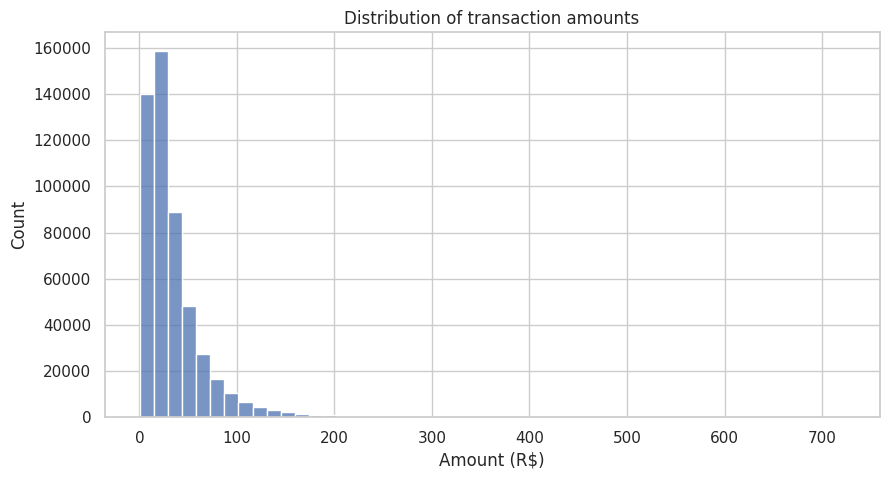

In [57]:
plt.figure(figsize=(10, 5))
sns.histplot(data2025['valor_transacao'], bins=50)
plt.title('Distribution of transaction amounts')
plt.xlabel('Amount (R$)')
plt.show()

### 2.4 Compatibility between 2025 and Jan/2026
*Goal: check whether Jan/2026 has categories that did not exist in 2025.*

In [58]:
text_columns_2025 = data2025.select_dtypes(include=['object']).columns
print(text_columns_2025.tolist())
print('-------')

for col in text_columns_2025:
    new_values = set(data2026[col]) - set(data2025[col])
    print(f"{col}: {data2025[col].nunique():,} categories in 2025 | {len(new_values):,} new in Jan/2026")

['nome_estabelecimento', 'tipo_estabelecimento', 'nome_cliente', 'cidade', 'device_type', 'codigo_postal', 'turno', 'valor_categoria', 'cidade_regiao']
-------
nome_estabelecimento: 10 categories in 2025 | 0 new in Jan/2026
tipo_estabelecimento: 6 categories in 2025 | 0 new in Jan/2026
nome_cliente: 26,214 categories in 2025 | 0 new in Jan/2026
cidade: 7 categories in 2025 | 0 new in Jan/2026
device_type: 3 categories in 2025 | 0 new in Jan/2026
codigo_postal: 521,905 categories in 2025 | 44,124 new in Jan/2026
turno: 4 categories in 2025 | 0 new in Jan/2026
valor_categoria: 3 categories in 2025 | 0 new in Jan/2026
cidade_regiao: 3 categories in 2025 | 0 new in Jan/2026


In [59]:
# comparing the means of the numeric columns between the two datasets
pd.DataFrame({'2025': data2025[['valor_transacao', 'score_interno', 'temperatura_celsius']].mean(),
              'jan/2026': data2026[['valor_transacao', 'score_interno', 'temperatura_celsius']].mean()}).round(2)

,2025,jan/2026
valor_transacao,43.96,44.13
score_interno,500.37,499.49
temperatura_celsius,24.01,23.98


**Section 2 conclusion:** The datasets are complete: there are no missing values or duplicated rows, and the date was converted to the right format (2025 covers the full year and Jan/2026 the full month). valor_transacao is highly skewed (mean of 44 and median of 25), which will be considered in the analysis and in the modeling.

Jan/2026 is compatible with 2025: there are no new categories (except codigo_postal), the means of the numeric variables are similar and all January customers already appear in the history, which allows creating customer behavior features. On the other hand, the codigo_postal values are very diverse, so it will be dropped from the modeling.

So, the model will be trained and evaluated with the 2025 data and then applied to classify the Jan/2026 transactions.

## 3. Exploratory analysis
Goal: understand the fraud rate and where it is concentrated (time, amount, device, merchant)

### 3.1 Fraud proportion

In [60]:
counts = data2025['flag_fraude'].value_counts()
proportion = data2025['flag_fraude'].value_counts(normalize=True)

print(counts)
print(proportion)

flag_fraude
False    503040
True      20485
Name: count, dtype: int64
flag_fraude
False    0.960871
True     0.039129
Name: proportion, dtype: float64


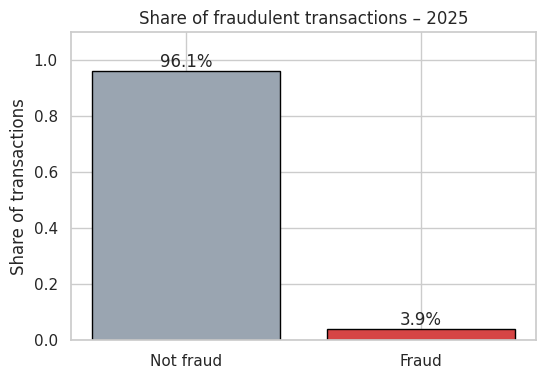

In [61]:
# Making the labels easier to read than True/False
proportion.index = proportion.index.map({False: 'Not fraud', True: 'Fraud'})

plt.figure(figsize=(6, 4))
bars = plt.bar(proportion.index, proportion.values,
               color=['#9aa5b1', '#d64545'], edgecolor='black')

# Writing the percentage on top of each bar
plt.bar_label(bars, labels=[f'{v:.1%}' for v in proportion.values])

plt.ylabel('Share of transactions')
plt.title('Share of fraudulent transactions – 2025')
plt.ylim(0, 1.1)
plt.show()

**Conclusion:** Only 3.9% of the transactions are fraud, so the dataset is imbalanced. That is why accuracy is not suitable to evaluate the model.

### 3.2 Fraud over time

In [62]:
data2025['month'] = data2025['datahora_transacao'].dt.month
rate_month = data2025.groupby('month')['flag_fraude'].mean()
print(rate_month)

month
1     0.037312
2     0.036950
3     0.038023
4     0.038208
5     0.036951
6     0.038190
7     0.039875
8     0.037145
9     0.037475
10    0.038072
11    0.036710
12    0.054239
Name: flag_fraude, dtype: float64


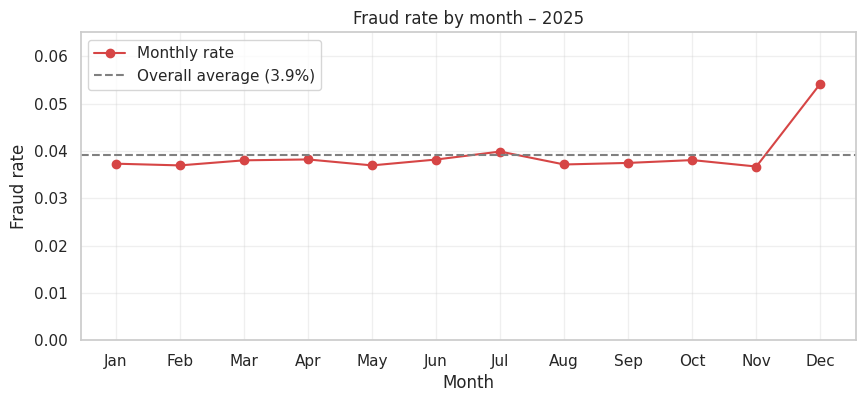

In [63]:
overall_rate = data2025['flag_fraude'].mean()
plt.figure(figsize=(10, 4))
rate_month.plot(kind='line', marker='o', color='#d64545', label='Monthly rate')
plt.axhline(overall_rate, color='gray', linestyle='--', label=f'Overall average ({overall_rate:.1%})')

plt.xticks(range(1, 13), ['Jan','Feb','Mar','Apr','May','Jun',
                          'Jul','Aug','Sep','Oct','Nov','Dec'])
plt.ylim(0, rate_month.max() * 1.2)
plt.xlabel('Month')
plt.ylabel('Fraud rate')
plt.title('Fraud rate by month – 2025')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Conclusion:** From January to November, the fraud rate is stable (between 3.7% and 4.0%). In December, it rises sharply to 5.4%, about 44% above a typical month. So we can form a hypothesis: year-end seasonality (more purchases, 13th salary) or a new attack pattern. Since Jan/2026 comes right after December, this behavior should be considered when evaluating the model.

### 3.3 Fraud and transaction amount

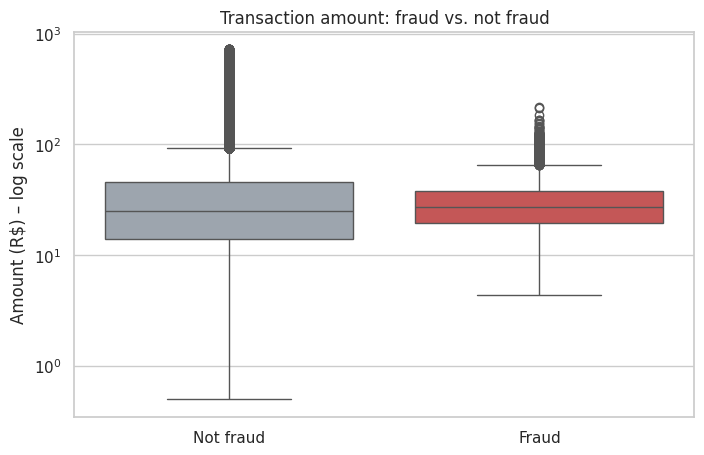

In [64]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=data2025, x='flag_fraude', y='valor_transacao',
            order=[False, True],
            hue='flag_fraude', legend=False,
            palette={False: '#9aa5b1', True: '#d64545'})
plt.yscale('log')
plt.xticks([0, 1], ['Not fraud', 'Fraud'])
plt.xlabel('')
plt.ylabel('Amount (R$) – log scale')
plt.title('Transaction amount: fraud vs. not fraud')
plt.show()

**Conclusion:** Frauds are not associated with high amounts: the medians are similar (25 vs. 27), but frauds are concentrated in an intermediate range (19 to 38) and none goes above 219, while there are legitimate transactions of up to 723.

### 3.4 Fraud and internal score

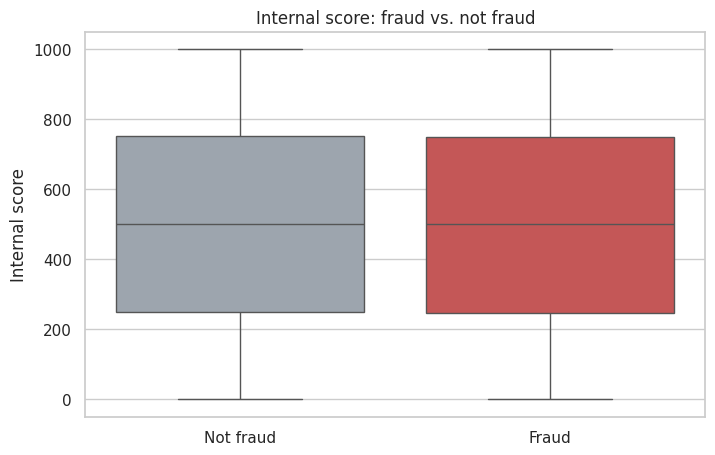

In [65]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=data2025, x='flag_fraude', y='score_interno',
            order=[False, True],
            hue='flag_fraude', legend=False,
            palette={False: '#9aa5b1', True: '#d64545'})
plt.xticks([0, 1], ['Not fraud', 'Fraud'])
plt.xlabel('')
plt.ylabel('Internal score')
plt.title('Internal score: fraud vs. not fraud')
plt.show()

In [66]:
# statistics of the amount and the score split by fraud / not fraud
data2025.groupby('flag_fraude')[['valor_transacao', 'score_interno']].describe().T.round(2)

flag_fraude                False     True 
valor_transacao count  503040.00  20485.00
                mean       44.50     30.86
                std        75.79     16.62
                min         0.50      4.41
                25%        14.03     19.41
                50%        25.11     27.21
                75%        45.43     37.96
                max       722.90    218.83
score_interno   count  503040.00  20485.00
                mean      500.42    499.34
                std       288.92    288.86
                min         0.00      0.00
                25%       250.00    247.00
                50%       500.00    501.00
                75%       751.00    750.00
                max      1000.00   1000.00

**Conclusion:** The distribution of score_interno is practically the same for frauds and legitimate transactions (medians of 501 and 500; quartiles from ~250 to ~750 in both). In other words, in this dataset the current score does not separate frauds from normal transactions, which reinforces the need for a model, and since its methodology is not known, it is recommended to check with the responsible team what it measures.

### 3.5 Fraud by category

Goal: compare the fraud rate across shifts, devices and merchant types.

In [67]:
categorical = data2025.select_dtypes(include=['object']).columns
print(categorical.tolist())

['nome_estabelecimento', 'tipo_estabelecimento', 'nome_cliente', 'cidade', 'device_type', 'codigo_postal', 'turno', 'valor_categoria', 'cidade_regiao']


In [68]:
data2025[categorical].nunique().sort_values()

,0
valor_categoria,3
device_type,3
cidade_regiao,3
turno,4
tipo_estabelecimento,6
cidade,7
nome_estabelecimento,10
nome_cliente,26214
codigo_postal,521905


In [69]:
def fraud_rate_chart(column):
    # 1. Computing the rate and volume of each category
    summary = data2025.groupby(column)['flag_fraude'].agg(['mean', 'count'])
    summary = summary.sort_values('mean')

    # 2. Drawing the bars
    plt.figure(figsize=(8, 0.6 * len(summary) + 1.5))
    bars = plt.barh(summary.index.astype(str), summary['mean'],
                    color='#d64545', edgecolor='black')

    # 3. Writing the rate next to each bar
    plt.bar_label(bars, labels=[f'{v:.1%}' for v in summary['mean']], padding=3)

    # 4. Overall average line
    plt.axvline(data2025['flag_fraude'].mean(), color='gray', linestyle='--',
                label='Overall average (3.9%)')

    plt.xlim(0, summary['mean'].max() * 1.25)
    plt.xlabel('Fraud rate')
    plt.title(f'Fraud rate by {column}')
    plt.legend(loc='lower right')
    plt.show()

    # 5. Showing the table too
    print(summary)

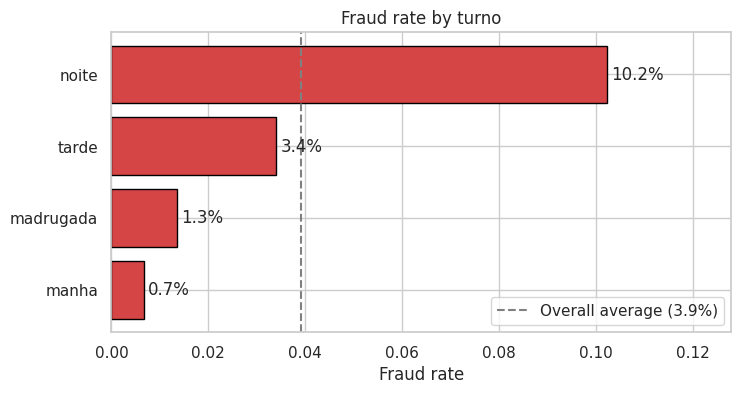

               mean   count
turno                      
manha      0.006637  130928
madrugada  0.013481  130850
tarde      0.033995  130871
noite      0.102410  130876


In [70]:
fraud_rate_chart('turno')

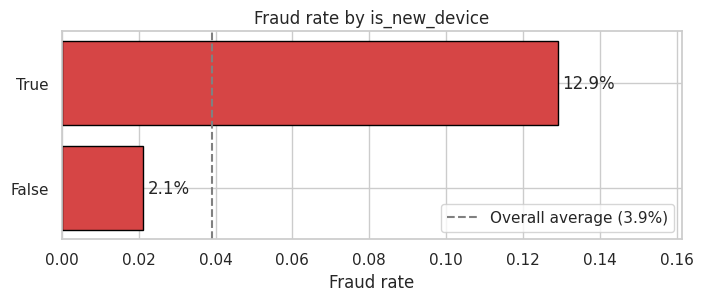

                   mean   count
is_new_device                  
False          0.021264  436704
True           0.128990   86821


In [71]:
fraud_rate_chart('is_new_device')

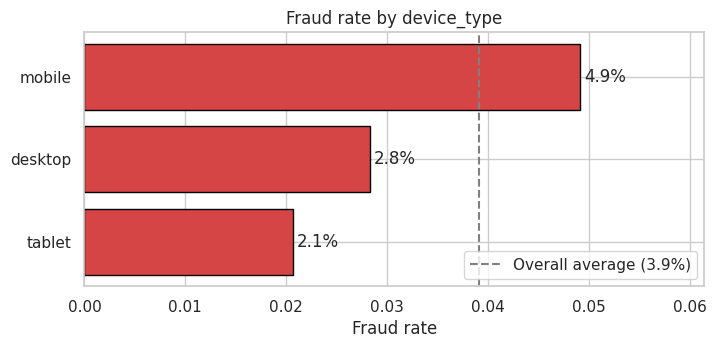

                 mean   count
device_type                  
tablet       0.020622   51207
desktop      0.028263  181262
mobile       0.049152  291056


In [72]:
fraud_rate_chart('device_type')

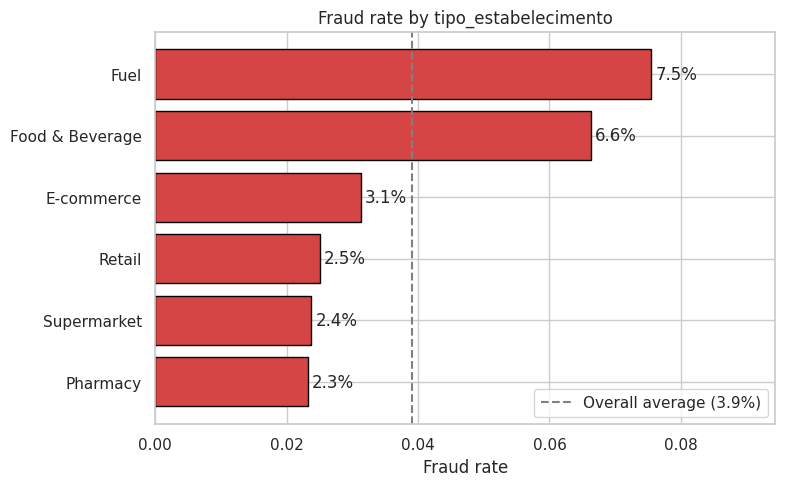

                          mean   count
tipo_estabelecimento                  
Pharmacy              0.023255   52591
Supermarket           0.023747  104225
Retail                0.025065  104648
E-commerce            0.031248  105223
Food & Beverage       0.066291  104675
Fuel                  0.075475   52163


In [73]:
fraud_rate_chart('tipo_estabelecimento')

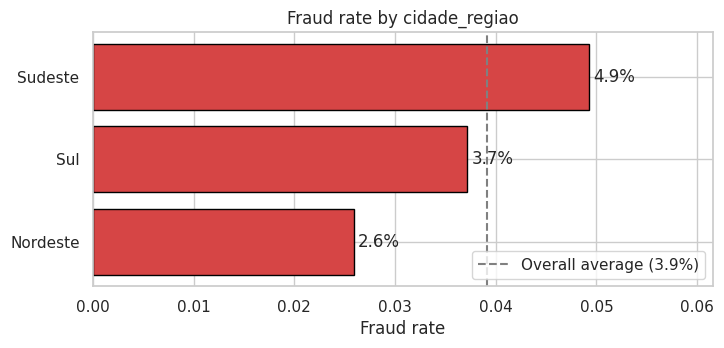

                   mean   count
cidade_regiao                  
Nordeste       0.025893  149425
Sul            0.037193  149976
Sudeste        0.049250  224124


In [74]:
fraud_rate_chart('cidade_regiao')

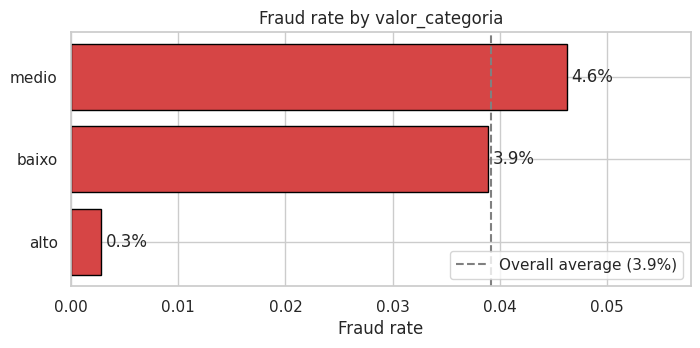

                     mean   count
valor_categoria                  
alto             0.002823   34362
baixo            0.038896  304015
medio            0.046249  185148


In [75]:
fraud_rate_chart('valor_categoria')

The analysis by category above shows strong signs:
*   Shift: at night the fraud rate is 10.2%, about 15 times higher than in the morning (0.7%).
*   Device: transactions on new devices have a rate of 12.9%, about 6 times higher than on known devices (2.1%). Among device types, mobile has the highest rate (4.9%).
*   Merchant: gas stations (7.5%) and food & beverage (6.6%) have rates about 3 times higher than pharmacies (2.3%), the lowest rate.
*   Region: the Southeast (4.9%) has almost twice the rate of the Northeast (2.6%).
*   Amount: the highest rate is in medium-value transactions (4.6%), about 16 times higher than in high-value ones (0.3%), which have almost no fraud.

Therefore, we can deduce the following hypothesis: the fraudster acts at times with less monitoring, with new devices, and avoids high amounts to go unnoticed.

## 4. Feature engineering
Goal: create new features from the data, without using information from the future.

### 4.1 Time features

In [76]:
for df in [data2025, data2026]:
    df['hour'] = df['datahora_transacao'].dt.hour
    df['weekday'] = df['datahora_transacao'].dt.dayofweek   # 0 = Monday ... 6 = Sunday

In [77]:
rate_hour = data2025.groupby('hour')['flag_fraude'].mean()
print(rate_hour)

hour
0     0.013349
1     0.013571
2     0.014672
3     0.012199
4     0.013938
5     0.013157
6     0.012558
7     0.012273
8     0.014986
9     0.000000
10    0.000000
11    0.000000
12    0.067070
13    0.067780
14    0.069114
15    0.000000
16    0.000000
17    0.000000
18    0.000000
19    0.000000
20    0.009309
21    0.011141
22    0.300436
23    0.293732
Name: flag_fraude, dtype: float64


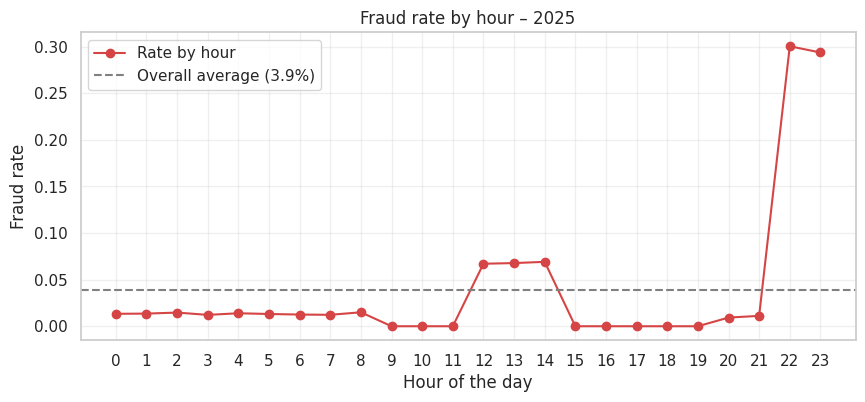

In [78]:
plt.figure(figsize=(10, 4))
rate_hour.plot(kind='line', marker='o', color='#d64545', label='Rate by hour')
plt.axhline(data2025['flag_fraude'].mean(), color='gray', linestyle='--',
            label=f"Overall average ({data2025['flag_fraude'].mean():.1%})")

plt.xticks(range(0, 24))
plt.xlabel('Hour of the day')
plt.ylabel('Fraud rate')
plt.title('Fraud rate by hour – 2025')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

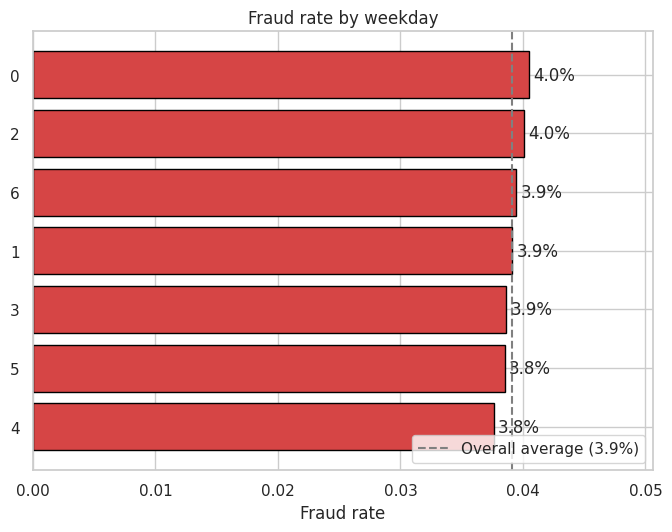

             mean  count
weekday                 
4        0.037626  74603
5        0.038500  74598
3        0.038624  74565
1        0.039125  74581
6        0.039451  74574
2        0.040072  76038
0        0.040488  74566


In [79]:
fraud_rate_chart('weekday')

**Conclusion:** The hour has a strong relationship with fraud. The peak is at 10 pm and 11 pm (rate of approx. 30%, about 7 times the average), and there is a smaller peak between 12 pm and 2 pm (approx. 7%). Between 9–11 am and 3–7 pm there are no frauds. The hour is more informative than the shift, which mixes very different risk hours (e.g., 8–9 pm with approx. 1% and 10–11 pm with approx. 30%). The day of the week did not show a relevant difference.

### 4.2 Customer history

In [80]:
data2025['source'] = '2025'
data2026['source'] = 'jan2026'
all_data = pd.concat([data2025, data2026], ignore_index=True)
all_data = all_data.sort_values('datahora_transacao').reset_index(drop=True)

by_customer = all_data.groupby('nome_cliente')

# number of purchases the customer made before this one
all_data['n_previous_transactions'] = by_customer.cumcount()

# average amount of the previous purchases (the current purchase is not included)
previous_sum = by_customer['valor_transacao'].cumsum() - all_data['valor_transacao']
all_data['previous_avg_amount'] = previous_sum / all_data['n_previous_transactions']

# current amount divided by the customer's previous average (1 = normal for this customer)
all_data['amount_to_avg_ratio'] = all_data['valor_transacao'] / all_data['previous_avg_amount']
all_data['amount_to_avg_ratio'] = all_data['amount_to_avg_ratio'].fillna(1)   # first purchase: neutral value

In [81]:
data2025 = all_data[all_data['source'] == '2025'].copy()
data2026 = all_data[all_data['source'] == 'jan2026'].copy()

data2025[['n_previous_transactions', 'previous_avg_amount', 'amount_to_avg_ratio']].describe()

,n_previous_transactions,previous_avg_amount,amount_to_avg_ratio
count,523525.000000,497311.000000,523525.000000
mean,9.982599,43.979217,1.326718
std,6.570388,31.963101,2.780678
min,0.000000,0.770000,0.004167
25%,4.000000,27.670238,0.360060
50%,9.000000,35.765556,0.722548
75%,15.000000,50.418125,1.274147
max,43.000000,722.900000,243.244131


In [82]:
# fraud rate by range of the ratio (purchase amount / customer average)
ranges = pd.qcut(data2025['amount_to_avg_ratio'], 5)
data2025.groupby(ranges, observed=True)['flag_fraude'].mean()

,flag_fraude
amount_to_avg_ratio,
"(0.00317, 0.303]",0.021632
"(0.303, 0.556]",0.044134
"(0.556, 0.944]",0.054954
"(0.944, 1.519]",0.048823
"(1.519, 243.244]",0.026102


**Conclusion:** The fraud rate is higher in the middle ranges, when the purchase amount is close to the customer's own average, and lower when the amount is much lower or much higher than usual. This suggests that the fraudster tries to imitate the customer's normal behavior to avoid drawing attention.

### 4.3 Feature selection

In [83]:
numeric_columns = ['valor_transacao', 'score_interno', 'temperatura_celsius',
                   'hour', 'weekday', 'n_previous_transactions', 'amount_to_avg_ratio']
categorical_columns = ['tipo_estabelecimento', 'cidade', 'device_type',
                       'is_new_device', 'turno', 'valor_categoria']
features = numeric_columns + categorical_columns
target = 'flag_fraude'

for df in [data2025, data2026]:
    df['is_new_device'] = df['is_new_device'].astype(str)
data2025[target] = data2025[target].astype(bool)

print("Model features:", len(features))

Model features: 13


13 features were selected for the model, leaving out the postal code (no pattern), the customer name (identifier), redundant columns (merchant name and region), the month (to avoid the model memorizing the calendar) and the helper columns. score_interno and the temperature were kept to check, in the model interpretation, whether they really do not contribute.

## 5. Train / test split
Goal: split the 2025 history respecting the time order.

In [84]:
train = data2025[data2025['month'] <= 10]   # January to October
test  = data2025[data2025['month'] >= 11]   # November and December

X_train, y_train = train[features], train[target]
X_test,  y_test  = test[features],  test[target]

print("Train:", X_train.shape, f"| fraud rate: {y_train.mean():.1%}")
print("Test: ", X_test.shape,  f"| fraud rate: {y_test.mean():.1%}")

Train: (436034, 13) | fraud rate: 3.8%
Test:  (87491, 13) | fraud rate: 4.6%


## 6. Modeling
Goal: train three models, from the simplest to the most complex (Logistic Regression, Random Forest and Gradient Boosting), and compare them with the internal score that already exists.

In [85]:
# turning the text columns into columns of 0 and 1
X_train_num = pd.get_dummies(X_train, columns=categorical_columns)
X_test_num = pd.get_dummies(X_test, columns=categorical_columns)

# making sure the test set has the same columns as the train set
X_test_num = X_test_num.reindex(columns=X_train_num.columns, fill_value=0)

print(X_train_num.shape, X_test_num.shape)

(436034, 32) (87491, 32)


### 6.1 Logistic Regression
First, a simple model, to have a baseline for comparison. Logistic Regression gives a weight to each feature and turns the result into a probability of fraud. Since it does the math directly with the numbers, I standardized the numeric features first, using only the training data so no information leaks from the test set.

In [86]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# standardizing the numeric columns (mean and std calculated only on the train set)
scaler = StandardScaler()
X_train_std = X_train_num.copy()
X_test_std = X_test_num.copy()
X_train_std[numeric_columns] = scaler.fit_transform(X_train_num[numeric_columns])
X_test_std[numeric_columns] = scaler.transform(X_test_num[numeric_columns])

# training the model
model_lr = LogisticRegression(max_iter=1000, class_weight='balanced')
model_lr.fit(X_train_std, y_train)
print("Model trained")

Model trained


### 6.2 Random Forest
Random Forest combines 100 decision trees. Each tree learns from a different part of the data and, at the end, they vote. This helps to prevent the model from memorizing the training data (overfitting). It does not need standardization, because trees do not depend on the scale of the numbers.

In [87]:
from sklearn.ensemble import RandomForestClassifier

# trees do not need standardization, so we use X_train_num directly
model_rf = RandomForestClassifier(n_estimators=100, min_samples_leaf=20,
                                  n_jobs=-1, random_state=42)
model_rf.fit(X_train_num, y_train)
print("Model trained!")

Model trained!


### 6.3 Gradient Boosting
A model widely used in fraud prevention. The trees are built in sequence, and each new tree focuses on correcting the errors of the previous ones.

In [88]:
from sklearn.ensemble import HistGradientBoostingClassifier

model_gb = HistGradientBoostingClassifier(random_state=42)
model_gb.fit(X_train_num, y_train)
print("Model trained!")

Model trained!


## 7. Evaluation
Goal: compare the models in the test period (Nov–Dec/2025), choose the best one and define the threshold.

Since the dataset is imbalanced (4.6% fraud in the test set), the main metric is Average Precision, which summarizes the Precision-Recall curve and does not depend on the threshold.

### 7.1 Comparing the models

In [89]:
from sklearn.metrics import average_precision_score, roc_auc_score

# fraud probability that each model gives to the test transactions
prob_lr = model_lr.predict_proba(X_test_std)[:, 1]
prob_rf = model_rf.predict_proba(X_test_num)[:, 1]
prob_gb = model_gb.predict_proba(X_test_num)[:, 1]

comparison = pd.DataFrame({
    'Model': ['Internal score', 'Logistic Regression', 'Random Forest', 'Gradient Boosting'],
    'Average Precision': [average_precision_score(y_test, test['score_interno']),
                          average_precision_score(y_test, prob_lr),
                          average_precision_score(y_test, prob_rf),
                          average_precision_score(y_test, prob_gb)],
    'AUC-ROC': [roc_auc_score(y_test, test['score_interno']),
                roc_auc_score(y_test, prob_lr),
                roc_auc_score(y_test, prob_rf),
                roc_auc_score(y_test, prob_gb)]
})
comparison.round(3)

,Model,Average Precision,AUC-ROC
0,Internal score,0.045,0.502
1,Logistic Regression,0.247,0.894
2,Random Forest,0.632,0.964
3,Gradient Boosting,0.624,0.958


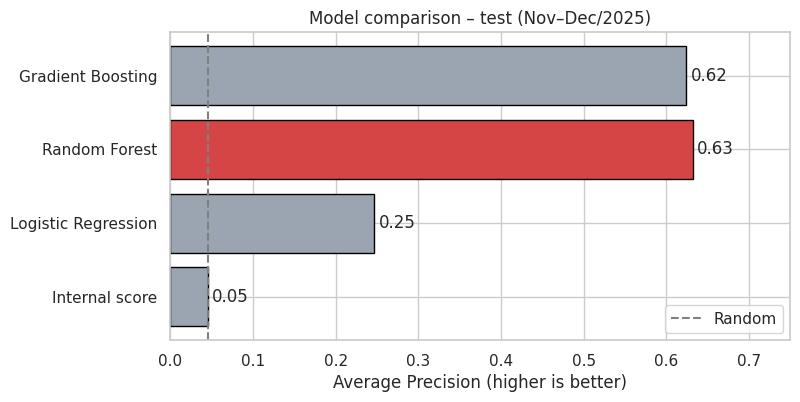

In [90]:
plt.figure(figsize=(8, 4))
bars = plt.barh(comparison['Model'], comparison['Average Precision'],
                color=['#9aa5b1', '#9aa5b1', '#d64545', '#9aa5b1'], edgecolor='black')
plt.bar_label(bars, labels=[f'{v:.2f}' for v in comparison['Average Precision']], padding=3)
plt.axvline(y_test.mean(), color='gray', linestyle='--', label='Random')
plt.xlim(0, 0.75)
plt.xlabel('Average Precision (higher is better)')
plt.title('Model comparison – test (Nov–Dec/2025)')
plt.legend()
plt.show()

### 7.2 Precision-Recall curve

The higher the curve, the better: the model detects the same number of frauds with fewer false alerts. Random Forest and Gradient Boosting practically overlap and are better than the others. The internal score stays on the random line.

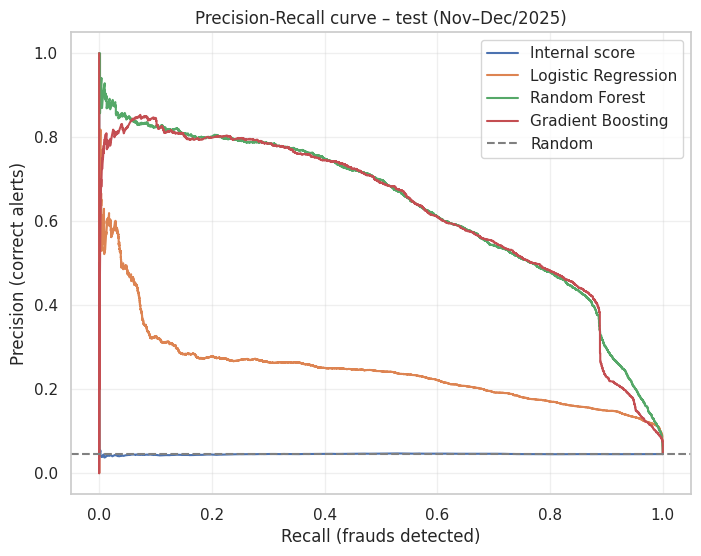

In [91]:
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(8, 6))

models = [('Internal score', test['score_interno']),
          ('Logistic Regression', prob_lr),
          ('Random Forest', prob_rf),
          ('Gradient Boosting', prob_gb)]

for name, prob in models:
    precision, recall, _ = precision_recall_curve(y_test, prob)
    plt.plot(recall, precision, label=name)

plt.axhline(y_test.mean(), color='gray', linestyle='--', label='Random')
plt.xlabel('Recall (frauds detected)')
plt.ylabel('Precision (correct alerts)')
plt.title('Precision-Recall curve – test (Nov–Dec/2025)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 7.3 ROC curve

The AUC confirms the order of the models (Random Forest: 0.96; internal score: 0.50). In imbalanced datasets the ROC tends to be optimistic, so it was used only as a complement.

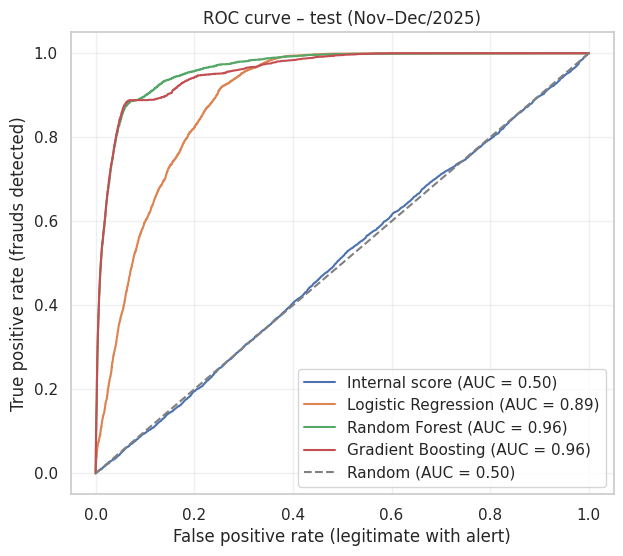

In [92]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(7, 6))

for name, prob in models:
    fp_rate, tp_rate, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fp_rate, tp_rate, label=f'{name} (AUC = {auc:.2f})')

plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random (AUC = 0.50)')
plt.xlabel('False positive rate (legitimate with alert)')
plt.ylabel('True positive rate (frauds detected)')
plt.title('ROC curve – test (Nov–Dec/2025)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 7.4 Choosing the model
Random Forest had the best performance on both metrics (Average Precision of 0.632 and AUC of 0.964), slightly above Gradient Boosting (about 0.62 and 0.96). Since the difference is small, simplicity also counted: Random Forest is easier to explain and interpret. From here on, the analysis considers only this model.

### 7.5 Threshold

The threshold turns the model probability into a decision (alert or not). A threshold of 0.2 was chosen, which detects ~78% of the frauds with ~50% correct alerts. The final choice should consider the cost of each error and the team's capacity.

In [93]:
precision, recall, thresholds = precision_recall_curve(y_test, prob_rf)

for t in [0.1, 0.2, 0.3, 0.4, 0.5]:
    position = abs(thresholds - t).argmin()
    print(f"Threshold {t} → precision {precision[position]:.0%} | recall {recall[position]:.0%}")

Threshold 0.1 → precision 40% | recall 87%
Threshold 0.2 → precision 50% | recall 78%
Threshold 0.3 → precision 61% | recall 60%
Threshold 0.4 → precision 70% | recall 50%
Threshold 0.5 → precision 74% | recall 42%


### 7.6 Confusion matrix

With a threshold of 0.2, the model detected 3,094 of the 3,991 frauds (77%), raising an alert on only 7.1% of the transactions.

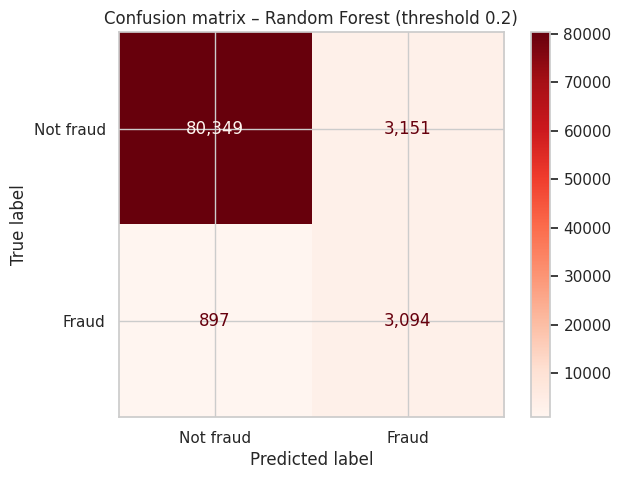

Frauds detected: 3094 of 3991
Transactions with alert: 7.1%


In [94]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

threshold = 0.2
prediction = prob_rf >= threshold

matrix = confusion_matrix(y_test, prediction)
ConfusionMatrixDisplay(matrix, display_labels=['Not fraud', 'Fraud']).plot(cmap='Reds', values_format=',')
plt.title('Confusion matrix – Random Forest (threshold 0.2)')
plt.show()

print("Frauds detected:", matrix[1, 1], "of", matrix[1].sum())
print(f"Transactions with alert: {prediction.mean():.1%}")

**Section 7 conclusion:**
- The internal score performs the same as random (Average Precision of 0.05; AUC of 0.50).
- Logistic Regression had limited performance (AP of 0.25), because it does not capture non-linear relationships, like frauds concentrated at 10 pm and 11 pm.
- Random Forest was the chosen model (AP of 0.63, AUC of 0.96), with performance about 14 times better than random and equivalent to Gradient Boosting, but simpler to interpret.
- With a threshold of 0.2, it detects 77% of the frauds (3,094 of 3,991), with about half of the alerts being confirmed frauds, raising alerts on only 7.1% of the transactions.

### 7.7 Can the model be improved?
To check if the result could be better, I tested some variations of the model: without the weak features, with more trees and a tuned Gradient Boosting.

In [95]:
# Testing a few model variations (to check if the model can be improved)
weak = ['score_interno', 'temperatura_celsius', 'weekday', 'n_previous_transactions']
cols_small = [c for c in X_train_num.columns if c not in weak]

tests = {
    'Random Forest (chosen)': (RandomForestClassifier(n_estimators=100, min_samples_leaf=20, n_jobs=-1, random_state=42), X_train_num.columns),
    'Without weak features': (RandomForestClassifier(n_estimators=100, min_samples_leaf=20, n_jobs=-1, random_state=42), cols_small),
    'More trees, smaller leaves': (RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42), cols_small),
    'Tuned Gradient Boosting': (HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400, random_state=42), cols_small),
}

for name, (model, cols) in tests.items():
    model.fit(X_train_num[cols], y_train)
    prob = model.predict_proba(X_test_num[cols])[:, 1]
    print(f"{name}: Average Precision = {average_precision_score(y_test, prob):.3f}")

Random Forest (chosen): Average Precision = 0.632
Without weak features: Average Precision = 0.633
More trees, smaller leaves: Average Precision = 0.618
Tuned Gradient Boosting: Average Precision = 0.630


**Conclusion:** None of the variations improved the result (all close to 0.63). So the model seems to be limited by the information in the data, not by the algorithm. To improve it, we would need new data, like device or location history.

## 8. Model interpretation
The most important feature is the hour (40% of the total importance), followed by new device, merchant type, shift and city. This result confirms the patterns found in the exploratory analysis. The internal score and the day of the week are among the least important features, also in line with the exploration.

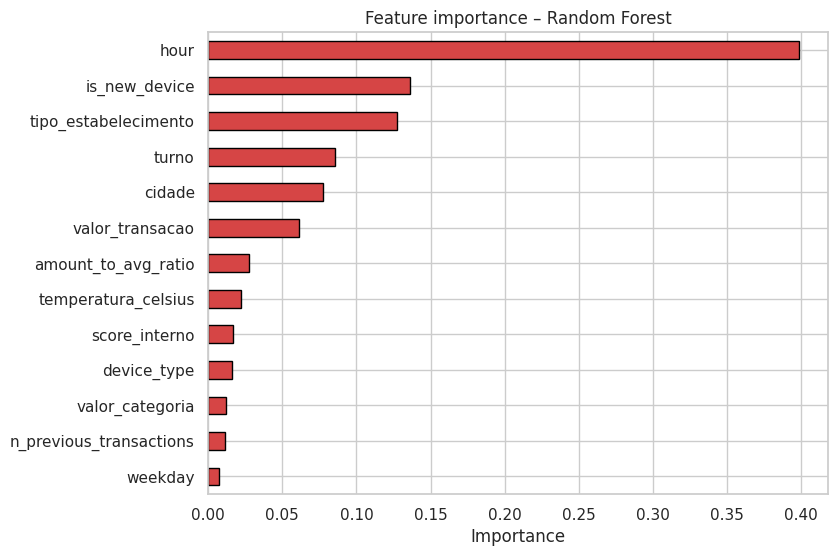

hour                       0.398
is_new_device              0.136
tipo_estabelecimento       0.128
turno                      0.085
cidade                     0.077
valor_transacao            0.061
amount_to_avg_ratio        0.027
temperatura_celsius        0.022
score_interno              0.017
device_type                0.016
valor_categoria            0.012
n_previous_transactions    0.011
weekday                    0.008
dtype: float64


In [96]:
# importance of each column (including the 0/1 columns created by get_dummies)
importance = pd.Series(model_rf.feature_importances_, index=X_train_num.columns)

# adding the 0/1 columns back into the original feature (e.g. turno_noite + turno_tarde... = turno)
grouped_importance = {}
for feat in features:
    feat_columns = [c for c in importance.index if c == feat or c.startswith(feat + '_')]
    grouped_importance[feat] = importance[feat_columns].sum()

grouped_importance = pd.Series(grouped_importance).sort_values()

plt.figure(figsize=(8, 6))
grouped_importance.plot(kind='barh', color='#d64545', edgecolor='black')
plt.xlabel('Importance')
plt.title('Feature importance – Random Forest')
plt.show()

print(grouped_importance.sort_values(ascending=False).round(3))

## 9. Classification of January/2026 and export

The Random Forest, with the same parameters evaluated in section 7, was retrained with the full 2025 history (including Nov–Dec, the most recent months and the closest to Jan/2026) and applied to the January transactions with a threshold of 0.2. 3,431 transactions (7.7%) were classified as potentially fraudulent, close to the share in the test period (7.1%), indicating a consistent behavior of the model.

The file `transactions_jan2026_classified.csv` has the original columns and two new ones:
- `fraud_probability`: estimated probability of fraud (0 to 1);
- `predicted_fraud`: final classification (True = fraud).

In [97]:
# 1. Preparing ALL of 2025 and January/2026 the same way (0/1 columns)
X_2025 = pd.get_dummies(data2025[features], columns=categorical_columns)
X_2026 = pd.get_dummies(data2026[features], columns=categorical_columns)
X_2026 = X_2026.reindex(columns=X_2025.columns, fill_value=0)

# 2. Training the final model with the full year of 2025
final_model = RandomForestClassifier(n_estimators=100, min_samples_leaf=20,
                                     n_jobs=-1, random_state=42)
final_model.fit(X_2025, data2025[target])

# 3. Classifying January/2026
data2026['fraud_probability'] = final_model.predict_proba(X_2026)[:, 1]
data2026['predicted_fraud'] = data2026['fraud_probability'] >= threshold

print("Transactions with alert:", data2026['predicted_fraud'].sum())
print(f"Share with alert: {data2026['predicted_fraud'].mean():.1%}")

# 4. Saving the CSV with the original columns + the classification
output_columns = ['datahora_transacao', 'nome_estabelecimento', 'tipo_estabelecimento',
                  'valor_transacao', 'nome_cliente', 'cidade', 'device_type', 'is_new_device',
                  'temperatura_celsius', 'codigo_postal', 'score_interno', 'turno',
                  'valor_categoria', 'cidade_regiao', 'fraud_probability', 'predicted_fraud']
data2026[output_columns].to_csv(folder + 'transactions_jan2026_classified.csv', index=False)
print("File saved to Drive!")

Transactions with alert: 3431
Share with alert: 7.7%
File saved to Drive!


In [98]:
check = pd.read_csv(folder + 'transactions_jan2026_classified.csv')
print(check.shape)
check.head()

(44451, 16)


,datahora_transacao,nome_estabelecimento,tipo_estabelecimento,valor_transacao,nome_cliente,cidade,device_type,is_new_device,temperatura_celsius,codigo_postal,score_interno,turno,valor_categoria,cidade_regiao,fraud_probability,predicted_fraud
0,2026-01-01 00:00:00,Pharmacy Z,Pharmacy,21.72,Cliente_16241,Curitiba,desktop,False,17.4,36135-417,691,madrugada,baixo,Sul,0.000000,False
1,2026-01-01 00:01:00,Electronics Store,Retail,28.70,Cliente_10027,Porto Alegre,mobile,False,11.9,83134-620,292,madrugada,baixo,Sul,0.000000,False
2,2026-01-01 00:02:00,Restaurant X,Food & Beverage,34.55,Cliente_13606,Porto Alegre,desktop,False,15.0,41309-759,81,madrugada,medio,Sul,0.000000,False
3,2026-01-01 00:03:00,Gas Station,Fuel,57.53,Cliente_7302,Belo Horizonte,desktop,False,23.5,15793-404,54,madrugada,medio,Sudeste,0.001433,False
4,2026-01-01 00:04:00,Gas Station,Fuel,149.50,Cliente_20061,Recife,desktop,False,28.1,73917-730,31,madrugada,alto,Nordeste,0.004437,False


## 10. Conclusions and next steps

**Main findings**
- Fraud is rare (3.9% of the transactions), but very concentrated: at 10 pm and 11 pm the rate reaches ~30%, and on new devices it is 6 times higher than on known devices.
- Gas stations and food & beverage have a rate about 3 times higher than pharmacies.
- Frauds avoid high amounts (none above R$ 219) and stay close to the customer's usual spending, suggesting an attempt to go unnoticed.
- In December, the fraud rate was 44% higher than in the other months.
- The current internal score does not separate frauds from legitimate transactions (performance equal to random).

**Model result**
Random Forest detects 77% of the frauds, with half of the alerts being confirmed frauds, raising alerts on only approximately 7% of the transactions. Its performance is about 14 times better than the current score.

**Recommendations**
- Use the model with risk ranges: automatic block for high probabilities, manual review for the intermediate ones and automatic approval for the low ones, reducing the team's manual work.
- Increase monitoring at 10 pm and 11 pm and on transactions with a new device.
- Review with the responsible team how the internal score is calculated.

**Limitations**
- The threshold was defined on the test set itself.
- The fraud label was considered reliable; it is recommended to validate the labeling criteria and timing with the team.
- The hourly patterns are very sharp and should be followed with future data.
- The final model was retrained with the full history; the results of section 7 are an estimate of its performance.

**Next steps**
- Retrain the model periodically (e.g., monthly) with the most recent data.
- Define the threshold based on the real cost of each type of error.
- Monitor the model performance month by month, since the fraud pattern can change.